# EDA and data cleaning — Constandino
Concert ticket purchase prediction (DSBA Kaggle challenge).

Part 1 of 2: exploring and cleaning the data. The cleaned data is saved at the end and loaded by `02_feature_engineering_constandino.ipynb`.

## Imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb

## Load data

In [2]:
# read train data
user_concert_train = pd.read_csv('../data/raw/train.csv')
user_concert_train.columns.to_list()

# read test data
user_concert_test = pd.read_csv('../data/raw/test.csv')
user_concert_test.columns.to_list()

['row_id',
 'user_id',
 'music_app_user_id',
 'age',
 'education',
 'spending_capacity_band',
 'home_city',
 'home_lat',
 'home_lon',
 'stated_favourite_genre',
 'past_purchase_count',
 'first_timer',
 'typical_ticket_spend',
 'usual_booking_lead_days',
 'concert_id',
 'artist_id',
 'artist_name',
 'genres',
 'venue_city',
 'venue_lat',
 'venue_lon',
 'concert_at',
 'sale_opened_at',
 'prediction_at',
 'ticket_price',
 'booking_fee',
 'discount_pct',
 'event_page_visits_7d',
 'wishlisted',
 'travel_search_city',
 'travel_search_arrival']

In [3]:
sample_submission = pd.read_csv('../data/raw/sample_submission.csv')
sample_submission.columns.to_list()
sample_submission.head()

,row_id,buy
0,R3770C503,0
1,R216C3DE0,0
2,R315CFF39,0
3,R0CC22A1C,0
4,R30EE7196,0


## First look

In [4]:
# EDA 
print(user_concert_train.shape) # 30k observations, 32 columns
print(user_concert_test.shape)  # 20k observations, 31 columns

(30000, 32)
(20000, 31)


In [5]:
#glimpse of data
user_concert_train.head()
user_concert_test.head()

,row_id,user_id,music_app_user_id,age,education,spending_capacity_band,home_city,home_lat,home_lon,stated_favourite_genre,...,concert_at,sale_opened_at,prediction_at,ticket_price,booking_fee,discount_pct,event_page_visits_7d,wishlisted,travel_search_city,travel_search_arrival
0,R3770C503,U3ACC7254,M0DE861B3,46,undergraduate,1,Lyon,45.764,4.835,folk_country,...,2026-11-10T20:00:00Z,2026-09-28T00:00:00Z,2026-10-01T00:00:00Z,85.00,10.10,0,0.0,0,Lyon,2026-11-10
1,R216C3DE0,U1C2E3AFA,M3B7890DA,47,undergraduate,5,Paris,48.857,2.352,rnb_soul,...,2026-11-10T20:00:00Z,2026-09-28T00:00:00Z,2026-10-01T00:00:00Z,106.25,11.38,0,0.0,1,NaN,NaN
2,R315CFF39,U1593B998,M17CA551F,46,undergraduate,3,Lyon,45.764,4.835,NaN,...,2026-12-12T20:00:00Z,2026-09-28T00:00:00Z,2026-10-01T00:00:00Z,93.75,10.62,10,1.0,0,NaN,NaN
3,R0CC22A1C,U15FCAF27,M1B1E629F,18,secondary,3,Rennes,48.117,-1.678,classical,...,2026-12-12T20:00:00Z,2026-09-28T00:00:00Z,2026-10-01T00:00:00Z,93.75,10.62,20,0.0,0,NaN,NaN
4,R30EE7196,U03D69656,M05B8CCEE,63,postgraduate,1,Lyon,45.764,4.835,alternative,...,2026-11-26T20:00:00Z,2026-09-28T00:00:00Z,2026-10-01T00:00:00Z,112.00,11.72,0,1.0,0,NaN,NaN


## Target balance

In [6]:
# target balance
user_concert_train.buy.value_counts() 
# class imbalance 2:1 on target data

buy
0    19914
1    10086
Name: count, dtype: int64

There's a mild imbalance, nothing crazy. lets hope the eval criteria in kaggle is good for this

In [7]:
#info
user_concert_train.info() 

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   row_id                   30000 non-null  str    
 1   user_id                  30000 non-null  str    
 2   music_app_user_id        28305 non-null  str    
 3   age                      30000 non-null  int64  
 4   education                30000 non-null  str    
 5   spending_capacity_band   30000 non-null  int64  
 6   home_city                30000 non-null  str    
 7   home_lat                 30000 non-null  float64
 8   home_lon                 30000 non-null  float64
 9   stated_favourite_genre   25375 non-null  str    
 10  past_purchase_count      30000 non-null  int64  
 11  first_timer              30000 non-null  int64  
 12  typical_ticket_spend     21760 non-null  float64
 13  usual_booking_lead_days  21760 non-null  float64
 14  concert_id               30000 no

## Summary statistics and extreme values (raw data, before filling the gaps)

In [8]:
user_concert_train.describe() # typical_ticket_spend, usual_booking_lead_days max values look extreme, inspect below

,age,spending_capacity_band,home_lat,home_lon,past_purchase_count,first_timer,typical_ticket_spend,usual_booking_lead_days,venue_lat,venue_lon,ticket_price,booking_fee,discount_pct,event_page_visits_7d,wishlisted,buy
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,21760.000000,21760.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,29137.000000,30000.00000,30000.000000
mean,41.406667,2.979333,47.303203,1.988091,2.896000,0.274667,141.411673,62.709789,47.461400,1.622200,99.986608,10.999195,4.534667,0.606583,0.16220,0.336200
std,13.884153,1.437118,2.113600,2.589645,2.320423,0.446354,72.679219,46.384167,2.088592,2.359991,27.056185,1.623555,6.723960,0.798631,0.36864,0.472416
min,18.000000,1.000000,43.604000,-1.678000,0.000000,0.000000,20.870000,3.500000,44.838000,-1.554000,60.000000,8.600000,0.000000,0.000000,0.00000,0.000000
25%,30.000000,2.000000,45.764000,-0.579000,0.000000,0.000000,90.937500,31.500000,45.764000,-0.579000,76.000000,9.560000,0.000000,0.000000,0.00000,0.000000
50%,41.000000,3.000000,48.117000,2.352000,3.000000,0.000000,125.462500,50.000000,47.218000,2.352000,95.000000,10.700000,0.000000,0.000000,0.00000,0.000000
75%,53.000000,4.000000,48.857000,3.057000,5.000000,1.000000,175.380000,79.000000,48.857000,3.057000,112.000000,11.720000,10.000000,1.000000,0.00000,1.000000
max,65.000000,5.000000,50.630000,7.752000,13.000000,1.000000,786.915000,497.000000,50.630000,4.835000,175.000000,15.500000,20.000000,6.000000,1.00000,1.000000


typical_ticket_spend (raw)
count 21760, mean 141.41, std 72.68, min 20.87, 25% 90.94, 50% 125.46, 75% 175.38, max 786.915 -- seems huge, have to inspect

usual_booking_lead_days (raw)
count 21760, mean 62.71, std 46.38, min 3.5, 25% 31.5, 50% 50, 75% 79, max 497 -- seems huge, have to inspect

(count is 21760, not 30000: the 8240 first-timers have no value yet, they are filled in the missing values section)

In [9]:
user_concert_train.nlargest(10, "typical_ticket_spend")[["user_id", "spending_capacity_band", "typical_ticket_spend", "past_purchase_count", "ticket_price", "buy"]] # not errors, but they’re extreme
user_concert_train.nlargest(10, "usual_booking_lead_days")[["user_id", "spending_capacity_band", "typical_ticket_spend", "past_purchase_count","usual_booking_lead_days", "ticket_price", "buy"]] # not errors, but they’re extreme

,user_id,spending_capacity_band,typical_ticket_spend,past_purchase_count,usual_booking_lead_days,ticket_price,buy
6632,U04B3BC26,2,146.545,4,497.0,131.25,0
10690,U04B3BC26,2,146.545,4,497.0,95.00,0
17138,U04B3BC26,2,146.545,4,497.0,75.00,0
19788,U04B3BC26,2,146.545,4,497.0,140.00,1
22131,U04B3BC26,2,146.545,4,497.0,85.00,0
1280,U14D3438E,4,233.725,4,467.0,85.00,1
14817,U14D3438E,4,233.725,4,467.0,140.00,1
17167,U14D3438E,4,233.725,4,467.0,95.00,0
21796,U14D3438E,4,233.725,4,467.0,105.00,0
26531,U14D3438E,4,233.725,4,467.0,93.75,1


## Pairplot of numeric columns

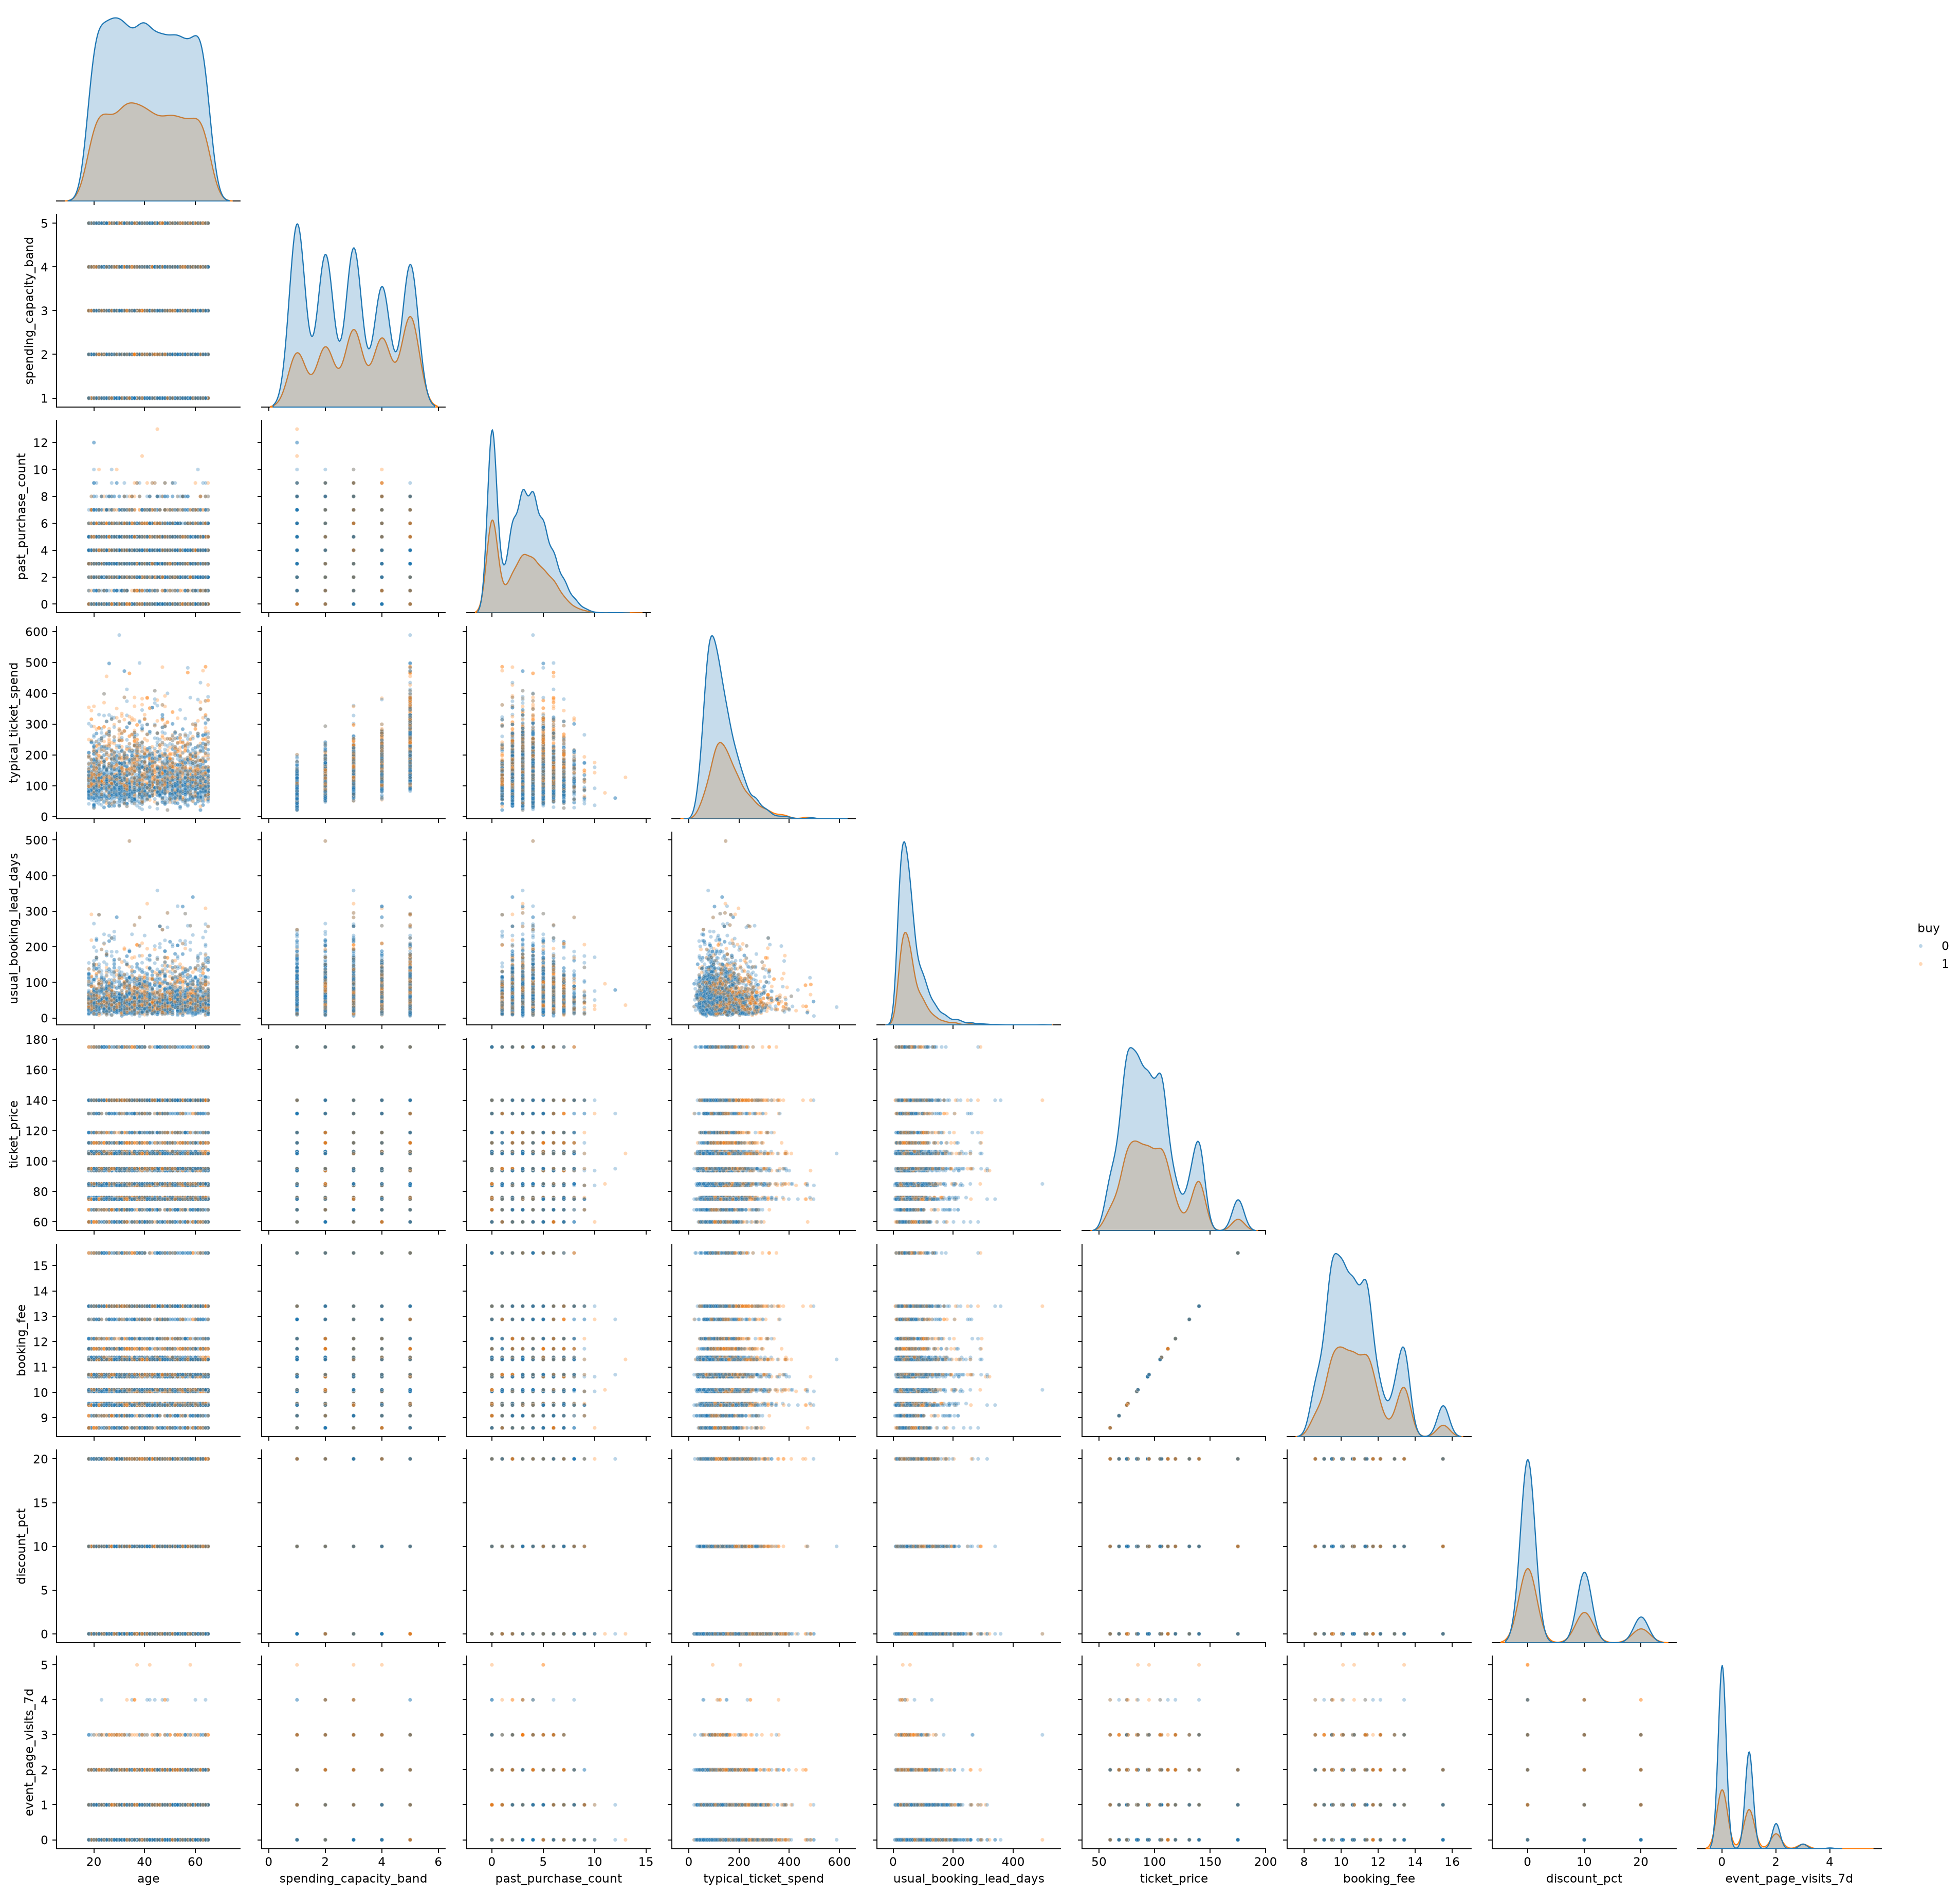

In [10]:
#sb.pairplot(user_concert_train) # check associations ( too large + I dont understand much)
#leave out the 0/1 flags, the IDs and the lat/lon columns, which only show up as rows of dots.

num_cols = ["age", "spending_capacity_band", "past_purchase_count", "typical_ticket_spend",
            "usual_booking_lead_days", "ticket_price", "booking_fee", "discount_pct",
            "event_page_visits_7d"]

sb.pairplot(
    user_concert_train[num_cols + ["buy"]].sample(5000, random_state=0), #using a random sample to avoid 30k rows
    hue="buy", corner=True, plot_kws={"alpha": 0.3, "s": 10},
)

Observations from the pairplot:
- a,booking fee and ticket price form a perfect line, so booking fee is an exact copy: drop it. Anything that doesnt show a relationship in the plot wont be omitted.
- b,The higher someone’s spending capacity band, the more likely they are to buy.
- c,Buyers tend to have a higher typical ticket spend.
- e,More event page visits go with more buying.

## Drop booking_fee

In [11]:
# booking_fee is an exact copy of ticket_price, ill drop it since correlation is exact
user_concert_train = user_concert_train.drop(columns=["booking_fee"])
user_concert_test = user_concert_test.drop(columns=["booking_fee"])

## Missing values

In [12]:
# find missing values
user_concert_train.isnull().sum()  # 7 columns with gaps, check why they are missing

row_id                         0
user_id                        0
music_app_user_id           1695
age                            0
education                      0
spending_capacity_band         0
home_city                      0
home_lat                       0
home_lon                       0
stated_favourite_genre      4625
past_purchase_count            0
first_timer                    0
typical_ticket_spend        8240
usual_booking_lead_days     8240
concert_id                     0
artist_id                      0
artist_name                    0
genres                         0
venue_city                     0
venue_lat                      0
venue_lon                      0
concert_at                     0
sale_opened_at                 0
prediction_at                  0
ticket_price                   0
discount_pct                   0
event_page_visits_7d         863
wishlisted                     0
travel_search_city         22496
travel_search_arrival      22496
buy       

### 1. music_app_user_id

In [13]:
#1. music_app_user_id
# count the percentage of rows that buy, grouped by non music app/music app user (True = no music app)
print(user_concert_train.groupby(user_concert_train["music_app_user_id"].isna())["buy"].mean())
# Missing music app id isn't random, no-account users buy 49% vs 33% with an account, so I keep it as a flag
user_concert_train["has_music_app"] = user_concert_train["music_app_user_id"].notna().astype(int)
user_concert_test["has_music_app"]  = user_concert_test["music_app_user_id"].notna().astype(int)

#test
print(user_concert_train[["music_app_user_id", "has_music_app"]].head(10))

music_app_user_id
False    0.326762
True     0.493805
Name: buy, dtype: float64
  music_app_user_id  has_music_app
0         M1B01D2D7              1
1         M1B2C63CC              1
2         M3AEF638D              1
3         M00C580ED              1
4         M29AC37E6              1
5         M28AC108F              1
6         M13848379              1
7         M0CC57650              1
8               NaN              0
9         M1950678C              1


### 2. stated_favourite_genre

In [14]:
# 2. stated_favourite_genre
print(user_concert_train.groupby(user_concert_train["stated_favourite_genre"].isna())["buy"].mean())
# Missing genre is random: buy rate 34.6% when missing vs 33.4% when given, so no flag needed,
# instead of omitting, ill replace with unknown because we dont know its strength as a predictor variable
user_concert_train["stated_favourite_genre"] = user_concert_train["stated_favourite_genre"].fillna("unknown")
user_concert_test["stated_favourite_genre"]  = user_concert_test["stated_favourite_genre"].fillna("unknown")


stated_favourite_genre
False    0.334463
True     0.345730
Name: buy, dtype: float64


### 3. event_page_visits_7d

In [15]:
# 3. event_page_visits_7d
print(user_concert_train.groupby(user_concert_train["event_page_visits_7d"].isna())["buy"].mean())
# Small gap: 30.8% when missing vs 33.7% -> keep a flag, fill with 0
user_concert_train["visits_missing"] = user_concert_train["event_page_visits_7d"].isna().astype(int)
user_concert_test["visits_missing"]  = user_concert_test["event_page_visits_7d"].isna().astype(int)
user_concert_train["event_page_visits_7d"] = user_concert_train["event_page_visits_7d"].fillna(0)
user_concert_test["event_page_visits_7d"]  = user_concert_test["event_page_visits_7d"].fillna(0)


#test
print(user_concert_train[["event_page_visits_7d", "visits_missing"]].head(10))

event_page_visits_7d
False    0.337029
True     0.308227
Name: buy, dtype: float64
   event_page_visits_7d  visits_missing
0                   0.0               0
1                   3.0               0
2                   1.0               0
3                   1.0               0
4                   0.0               0
5                   0.0               0
6                   0.0               0
7                   1.0               0
8                   2.0               0
9                   0.0               1


### 4. travel_search_city / travel_search_arrival

In [16]:
# 4. travel_search_city / travel_search_arrival
print(user_concert_train.groupby(user_concert_train["travel_search_city"].isna())["buy"].mean())
# Not random: people who searched travel buy 38.3% vs 32.1% who didn't so keep a flag, fill with "none"
user_concert_train["searched_travel"] = user_concert_train["travel_search_city"].notna().astype(int)
user_concert_test["searched_travel"]  = user_concert_test["travel_search_city"].notna().astype(int)
for c in ["travel_search_city", "travel_search_arrival"]:
    user_concert_train[c] = user_concert_train[c].fillna("none")
    user_concert_test[c]  = user_concert_test[c].fillna("none")

travel_search_city
False    0.383262
True     0.320501
Name: buy, dtype: float64


### 5. typical_ticket_spend / usual_booking_lead_days

In [17]:
# 5. typical_ticket_spend / usual_booking_lead_days
## crosstab: typical_ticket_spend missing (True/False) vs first_timer -> all missing rows should fall under first_timer = 1
print(pd.crosstab(user_concert_train["typical_ticket_spend"].isna(), user_concert_train["first_timer"]))
# Not random because missing exactly for first-timers (no past tickets to average),
# first_timer already flags them, so fill with the median (from train, used for test too)
for c in ["typical_ticket_spend", "usual_booking_lead_days"]:   # do the same for both columns
    med = user_concert_train[c].median()                         # middle value of that column in train
    user_concert_train[c] = user_concert_train[c].fillna(med)   # replace empty cells in train with it
    user_concert_test[c]  = user_concert_test[c].fillna(med)    # same median for test

first_timer               0     1
typical_ticket_spend             
False                 21760     0
True                      0  8240


Picked median because the gaps are exactly the first-timers, who have no past tickets to average, so the value can't exist for them. Dropping them would lose a quarter of the data, and the test set has first-timers we still need to predict. Median rather than mean because spend is right-skewed, and the `first_timer` column already flags those rows.

## Spearman correlation heatmap

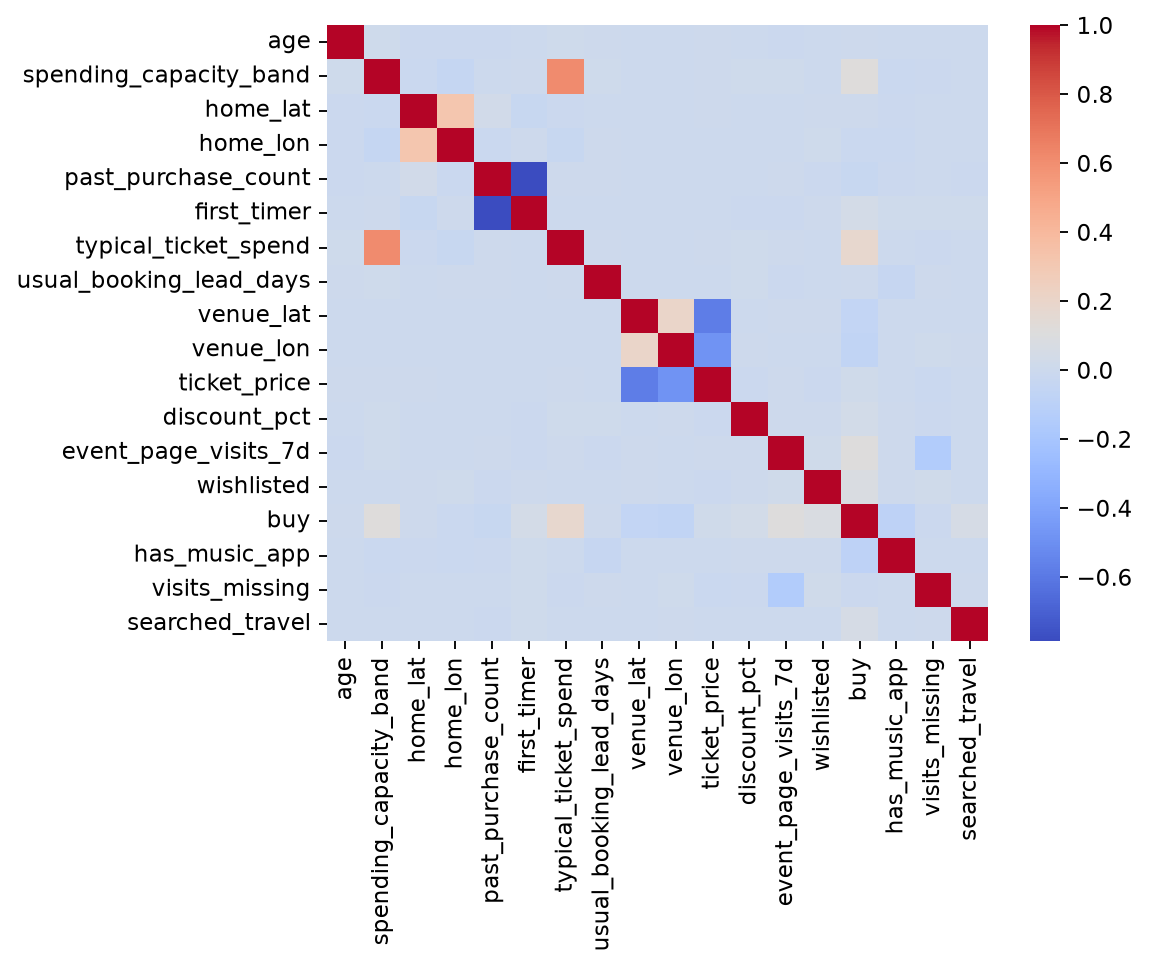

In [18]:
# use spearman because some distributions are skewed, using this to support my observations above (a,b,c,d,e)
sb.heatmap(user_concert_train.corr(method="spearman", numeric_only=True), cmap="coolwarm")
plt.show() 

## Buy rate by categorical column

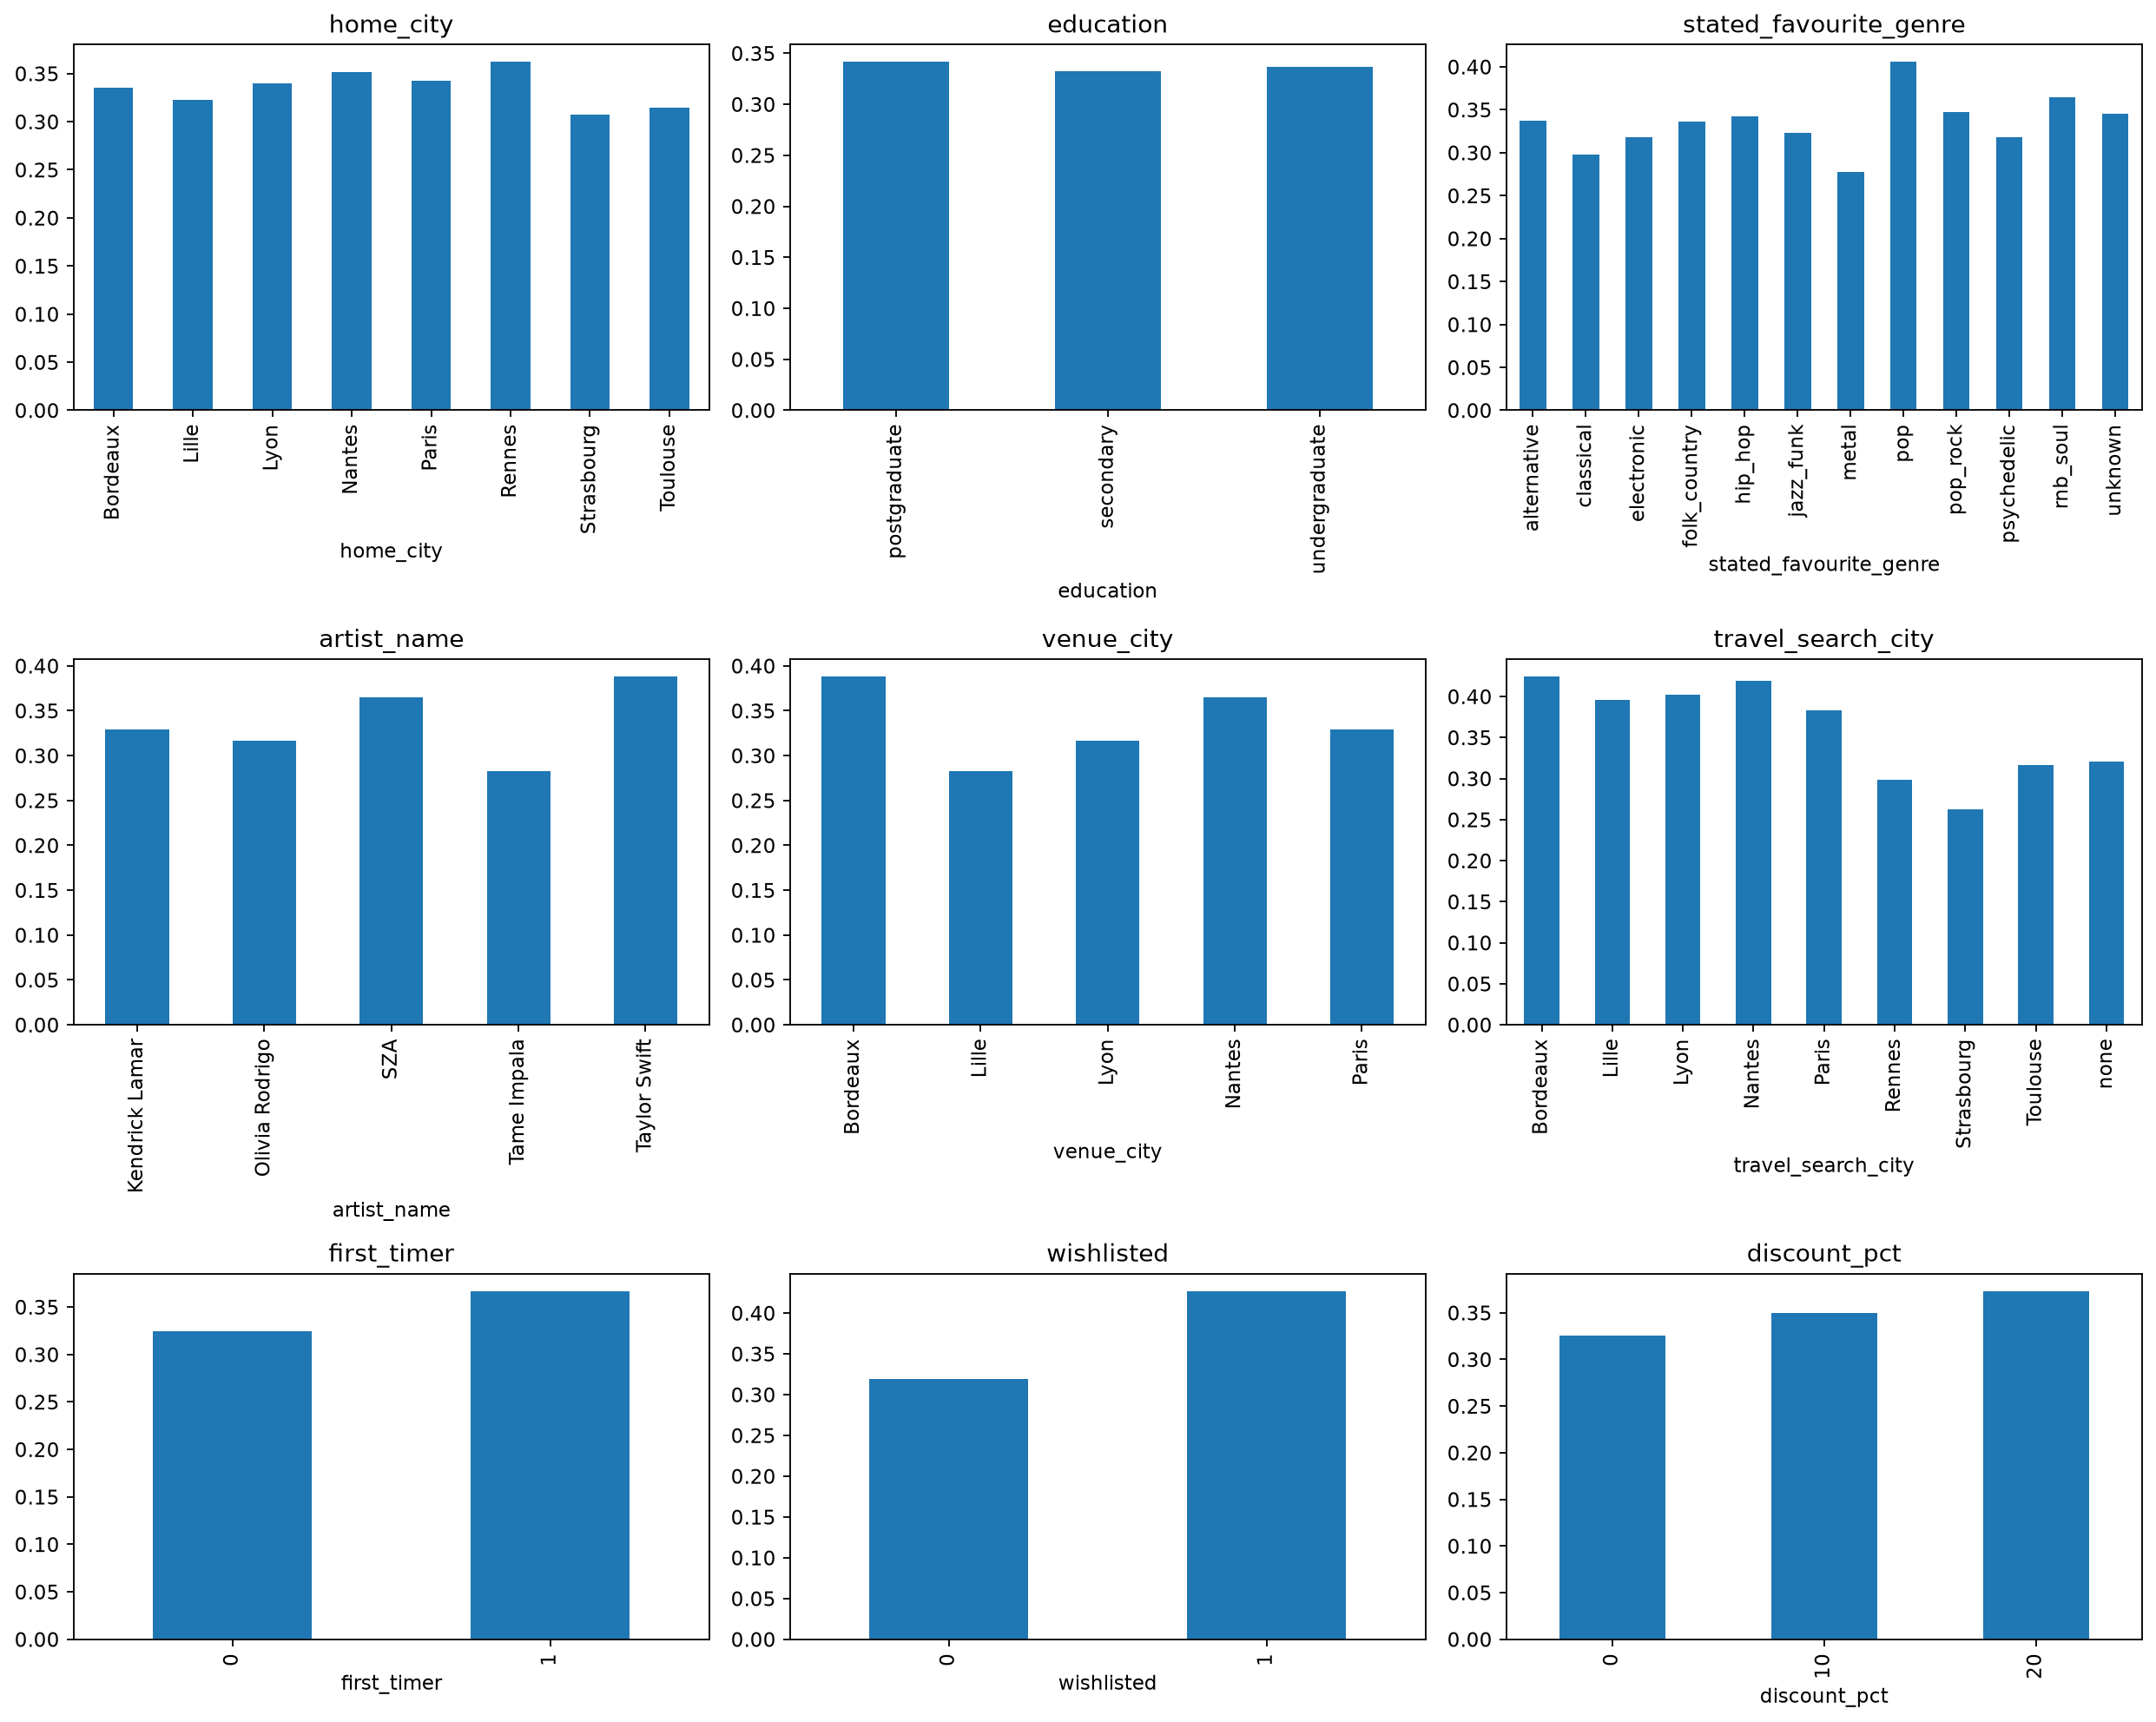

In [19]:
# categorical columns for analysis 
cols = ["home_city", "education", "stated_favourite_genre", "artist_name",
        "venue_city", "travel_search_city", "first_timer", "wishlisted", "discount_pct"]

## 
fig, axes = plt.subplots(3, 3, figsize=(15, 12)) # 3 rows x 3 columns
for col, ax in zip(cols, axes.flat): # loop through columns, and pair each with the box and grid 
     # buyers divided by all rows for that value: ex: filter for bordeaux and count observations with buy =1 over all filtered bordeaux observations
    user_concert_train.groupby(col)["buy"].mean().plot(kind="bar", ax=ax, title=col)
plt.tight_layout()
plt.show()

Observations:
- Home city: small differences (Rennes about 36%, Strasbourg about 31%), so it's weak on its own.
- Education: no difference, so it's the weakest column.
- Favourite genre: pop fans buy most (41%), metal and classical least, so genre match is likely useful.
- Artist: Taylor Swift highest (39%), Tame Impala lowest (28%).
- Venue city looks identical as artist, just different permutation -- * ill do analysis on this
- Travel search: searching for a concert city means about 40% buy, other cities about 30%, the same as not searching.
- Discount: buying rises with bigger discounts.
- Wishlisted: 43% versus 32%, the strongest flag.
- First timers: buy slightly more, 37% versus 32%.

In [20]:
#Venue city looks identical as artist, just different permutation -- * ill do analysis on this
pd.crosstab(user_concert_train["artist_name"], user_concert_train["venue_city"])


venue_city,Bordeaux,Lille,Lyon,Nantes,Paris
artist_name,,,,,
Kendrick Lamar,0,0,0,0,6000
Olivia Rodrigo,0,0,6000,0,0
SZA,0,0,0,6000,0
Tame Impala,0,6000,0,0,0
Taylor Swift,6000,0,0,0,0


Each artist has 6000 rows in exactly one city and 0 everywhere else so artist and city are a perfect one-to-one match: keep for now, maybe its useful for creating new features

## Final check: no missing values left

In [21]:
#check missing values ok
user_concert_train.isnull().sum()

row_id                        0
user_id                       0
music_app_user_id          1695
age                           0
education                     0
spending_capacity_band        0
home_city                     0
home_lat                      0
home_lon                      0
stated_favourite_genre        0
past_purchase_count           0
first_timer                   0
typical_ticket_spend          0
usual_booking_lead_days       0
concert_id                    0
artist_id                     0
artist_name                   0
genres                        0
venue_city                    0
venue_lat                     0
venue_lon                     0
concert_at                    0
sale_opened_at                0
prediction_at                 0
ticket_price                  0
discount_pct                  0
event_page_visits_7d          0
wishlisted                    0
travel_search_city            0
travel_search_arrival         0
buy                           0
has_musi

In [22]:
user_concert_test.isnull().sum()

row_id                        0
user_id                       0
music_app_user_id          1145
age                           0
education                     0
spending_capacity_band        0
home_city                     0
home_lat                      0
home_lon                      0
stated_favourite_genre        0
past_purchase_count           0
first_timer                   0
typical_ticket_spend          0
usual_booking_lead_days       0
concert_id                    0
artist_id                     0
artist_name                   0
genres                        0
venue_city                    0
venue_lat                     0
venue_lon                     0
concert_at                    0
sale_opened_at                0
prediction_at                 0
ticket_price                  0
discount_pct                  0
event_page_visits_7d          0
wishlisted                    0
travel_search_city            0
travel_search_arrival         0
has_music_app                 0
visits_m

## Save the cleaned data
Used by `02_feature_engineering_constandino.ipynb` (the CSVs stay out of git thanks to `.gitignore`).

In [23]:
user_concert_train.to_csv("../data/processed/train_clean.csv", index=False)
user_concert_test.to_csv("../data/processed/test_clean.csv", index=False)
print(user_concert_train.shape, user_concert_test.shape)

(30000, 34) (20000, 33)
